<a href="https://colab.research.google.com/github/saturnsz/Karhutla-2026-machine-learning-/blob/main/Karhutla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, cohen_kappa_score, mean_squared_error, roc_auc_score
import joblib
import warnings
warnings.filterwarnings('ignore')

In [2]:
print("1. Membaca dan Menyiapkan Data...")
df = pd.read_csv('/content/drive/MyDrive/fire_nrt_M-C61_825606.csv')

1. Membaca dan Menyiapkan Data...


In [3]:
df_kalimantan = df[
    (df['latitude'] >= -4.5) & (df['latitude'] <= 4.5) &
    (df['longitude'] >= 108.5) & (df['longitude'] <= 119.5)
].copy()
df_kalimantan = df_kalimantan[df_kalimantan['confidence'] >= 80].copy()

In [4]:
df_kalimantan['target_risk'] = np.where(df_kalimantan['frp'] > 30, 1, 0)

In [5]:
X = df_kalimantan[['latitude', 'longitude', 'brightness', 'confidence']]
y = df_kalimantan['target_risk']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [7]:
models = {
    'Decision Tree (DT)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Logistic Regression (MLR)': LogisticRegression(max_iter=1000, random_state=42),
    'Naive Bayes (NB)': GaussianNB()
}

print("\n2. Melatih Model dan Menghitung Metrik Evaluasi (Berdasarkan Jurnal)...\n")
results = []

for name, model in models.items():
    # Proses Training
    model.fit(X_train, y_train)

    # Proses Prediksi (Validation)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Menghitung Metrik Jurnal (ACC, SST, SPF, Kappa, RMSE, AUC)
    acc = accuracy_score(y_test, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    sensitivity = tp / (tp + fn) # SST (True Positive Rate)
    specificity = tn / (tn + fp) # SPF (True Negative Rate)
    kappa = cohen_kappa_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_prob))
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'SST (%)': round(sensitivity * 100, 2),
        'SPF (%)': round(specificity * 100, 2),
        'Kappa': round(kappa, 3),
        'RMSE': round(rmse, 3),
        'AUC': round(auc, 3)
    })

# Menampilkan Tabel Komparasi Hasil
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))


2. Melatih Model dan Menghitung Metrik Evaluasi (Berdasarkan Jurnal)...

                    Model  Accuracy (%)  SST (%)  SPF (%)  Kappa  RMSE   AUC
       Decision Tree (DT)         82.09    70.53    94.79  0.645 0.351 0.888
Logistic Regression (MLR)         81.19    79.45    83.09  0.624 0.361 0.888
         Naive Bayes (NB)         82.74    73.72    92.66  0.657 0.355 0.884


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

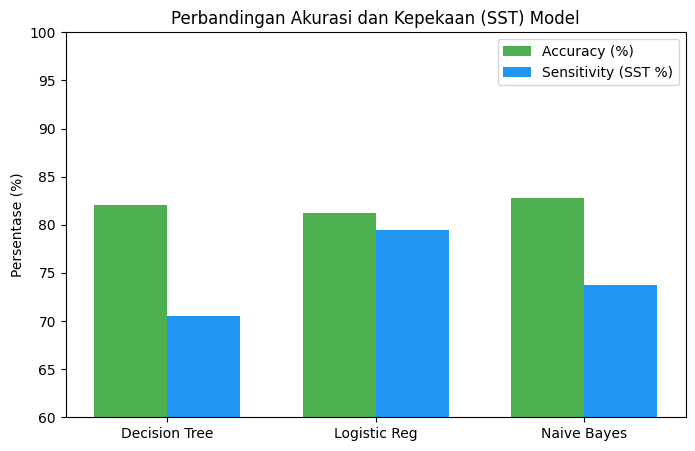

In [9]:
models = ['Decision Tree', 'Logistic Reg', 'Naive Bayes']
accuracy = [82.09, 81.19, 82.74]
sst = [70.53, 79.45, 73.72]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, accuracy, width, label='Accuracy (%)', color='#4CAF50')
rects2 = ax.bar(x + width/2, sst, width, label='Sensitivity (SST %)', color='#2196F3')

ax.set_ylabel('Persentase (%)')
ax.set_title('Perbandingan Akurasi dan Kepekaan (SST) Model')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(60, 100)
ax.legend()

In [10]:
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>


Memproses Peta...


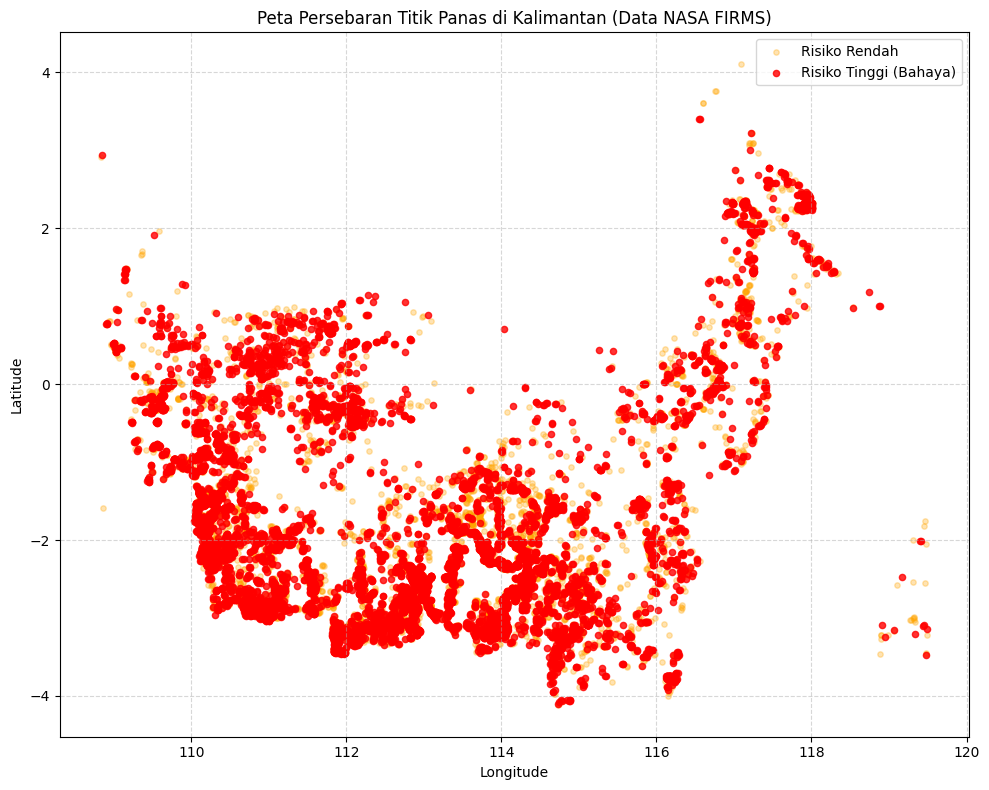

In [12]:
print("\nMemproses Peta...")
df = pd.read_csv('/content/drive/MyDrive/fire_nrt_M-C61_825606.csv')

# Filter Kalimantan & Kepercayaan Tinggi
df_kalimantan = df[
    (df['latitude'] >= -4.5) & (df['latitude'] <= 4.5) &
    (df['longitude'] >= 108.5) & (df['longitude'] <= 119.5)
].copy()
df_kalimantan = df_kalimantan[df_kalimantan['confidence'] >= 80].copy()

# Label Risiko
df_kalimantan['target_risk'] = np.where(df_kalimantan['frp'] > 30, 1, 0)

plt.figure(figsize=(10, 8))

# Plot Risiko Rendah (Oranye)
plt.scatter(df_kalimantan[df_kalimantan['target_risk']==0]['longitude'],
            df_kalimantan[df_kalimantan['target_risk']==0]['latitude'],
            c='orange', label='Risiko Rendah', alpha=0.3, s=15)

# Plot Risiko Tinggi (Merah)
plt.scatter(df_kalimantan[df_kalimantan['target_risk']==1]['longitude'],
            df_kalimantan[df_kalimantan['target_risk']==1]['latitude'],
            c='red', label='Risiko Tinggi (Bahaya)', alpha=0.8, s=20)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Peta Persebaran Titik Panas di Kalimantan (Data NASA FIRMS)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()